# Fusion Perception — Inference

Runs detection, tracking, Gemma reasoning, and evaluation on KITTI-360 data.

**Prerequisites:** run `pipeline_finetune.ipynb` once to download data and checkpoints.

**Run All** works on a fresh Colab session — no manual steps needed.

In [1]:
# Cell 1 — Mount Google Drive and navigate to project
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = '/content/drive/MyDrive/Fusion_sensor'   # ← edit if needed
os.chdir(PROJECT_DIR)
print(f'Working directory: {os.getcwd()}')

Mounted at /content/drive
Working directory: /content/drive/MyDrive/Fusion_sensor


In [2]:
# Cell 2 — Install all dependencies (~3 minutes)

import os
os.chdir('/content')   # prevent Drive FUSE OSError 107 during large pip writes

# 0 — pin setuptools
!pip install "setuptools<82" -q

# 1 — DO NOT reinstall torch. Use Colab's preinstalled build.
import torch
print(f"Runtime torch: {torch.__version__}")

# 2 — transformers upgrade (required for Gemma 4)
!pip install --upgrade transformers -q

# 3 — all project deps (pure pip, no compilation)
!pip install omegaconf>=2.3.0 opencv-python>=4.9.0 Pillow>=10.0.0 \
    dataclasses-json>=0.6.0 rich>=13.0.0 \
    huggingface_hub>=0.26.0 transformers>=4.47.0 \
    bitsandbytes>=0.44.0 accelerate>=1.2.0 \
    peft>=0.14.0 trl>=0.12.0 datasets>=3.0.0 \
    matplotlib>=3.8.0 filterpy>=1.4.5 \
    portalocker einops timm \
    ultralytics>=8.3.0 open3d>=0.18.0 kitti360scripts -q

# 4 — CoWTracker (optional — tracker falls back to KF-only if build fails)
!pip install git+https://github.com/facebookresearch/co-tracker -q \
    || echo "WARNING: CoWTracker install failed — tracker will run in KF-only mode."

# NOTE: openpifpaf (car keypoints) is disabled — no Python 3.12 wheels available.
#       Vehicle orientation uses PCA on instance-segmented LiDAR frustum instead.

# 5 — verify ultralytics
import importlib; importlib.invalidate_caches()
try:
    from ultralytics import YOLO
    print(f"ultralytics ready.")
except ImportError as e:
    raise RuntimeError(f"ultralytics not importable: {e}")

# 6 — repair Colab system packages
!pip install -U requests==2.32.4 urllib3 tqdm rich -q

# 7 — local project package
_project_dir = '/content/drive/MyDrive/Fusion_sensor'
!pip install -e {_project_dir} -q 2>/dev/null \
    || python -c "import sys; sys.path.insert(0, '{_project_dir}'); print('Project added to path.')"

os.chdir(_project_dir)
print(f'Working directory: {os.getcwd()}')
print('Installation complete.')

Runtime torch: 2.11.0+cu128
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 156.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics ready.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.1/131.1 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310.7 kB 35.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.40.0 requires rich<14,>=12.4.4, but you have rich 15.0.0 which is incompatible.
pyiceberg 0.11.1 requires rich<15.0.0,>=10.11.0, but you have rich 15.0.0 which is incompati

In [3]:
# Cell 3 — Verify GPU
import torch

assert torch.cuda.is_available(), 'No GPU — switch runtime to T4'
vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f'GPU:  {torch.cuda.get_device_name(0)}')
print(f'VRAM: {vram_gb:.1f} GB')
assert vram_gb >= 10.0, f'Need >= 10 GB VRAM, got {vram_gb:.1f} GB'
print('GPU check passed')

GPU:  NVIDIA L4
VRAM: 23.7 GB
GPU check passed


In [4]:
# Cell 4 — Pipeline configuration
import os, datetime
import numpy as np
from pathlib import Path

# ── Data source ──────────────────────────────────────────────────────────
# Set DATA_FORMAT to 'raw' for KITTI raw, '360' for KITTI-360.
DATA_FORMAT   = '360'                              # 'raw' | '360'

# KITTI raw (only used when DATA_FORMAT='raw')
DATA_PATH_ROOT = '2011_10_03'
DRIVE_SEQ      = '2011_10_03_drive_0047_sync'

# KITTI-360 (only used when DATA_FORMAT='360')
KITTI360_ROOT = '/content/drive/MyDrive/Fusion_sensor/KITTI-360'
KITTI360_SEQ  = '2013_05_28_drive_0000_sync'

MAX_FRAMES    = 500   # None = full sequence; int to cap
REASONING_INTERVAL = 15

VIDEO_PATH = (
    f'/content/kitti360_{KITTI360_SEQ}.mp4' if DATA_FORMAT == '360'
    else '/content/kitti_0047.mp4'
)

run_id  = datetime.datetime.now().strftime('%Y-%m-%d_%H%M%S') + '_' + (
    KITTI360_SEQ if DATA_FORMAT == '360' else DRIVE_SEQ
)
out_dir = Path('outputs') / run_id
out_dir.mkdir(parents=True, exist_ok=True)
print(f'Run ID     : {run_id}')
print(f'Output     : {out_dir}')
print(f'Data format: {DATA_FORMAT}')

SHOW_DEBUG        = True
DEBUG_EVERY       = 50
ENABLE_GT_EVAL    = True
SAVE_DEBUG_FRAMES = True


Run ID     : 2026-06-02_201954_2013_05_28_drive_0000_sync
Output     : outputs/2026-06-02_201954_2013_05_28_drive_0000_sync
Data format: 360


In [5]:
# Cell 5 — Detector: no checkpoint download needed
#
# FrustumLidarDetector uses a standard YOLO model (yolo11n.pt) which
# ultralytics downloads automatically on first use (~6 MB).
# No manual download step required.

import os
os.makedirs('ckpt', exist_ok=True)
print('ckpt/ directory ready.')
print('YOLO model will be downloaded automatically on first detector.load().')

ckpt/ directory ready.
YOLO model will be downloaded automatically on first detector.load().


In [6]:
# Cell 7 — Parse calibration → real 3×3 intrinsics K
if DATA_FORMAT == '360':
    if KITTI360_ROOT is None:
        raise ValueError("Set KITTI360_ROOT in cell-pipeline-config before running this cell.")
    from kitti360scripts.devkits.commons.loadCalibration import loadPerspectiveIntrinsic
    _intr = loadPerspectiveIntrinsic(f'{KITTI360_ROOT}/calibration/perspective.txt')
    K = np.asarray(_intr['P_rect_00'], dtype=np.float32)[:3, :3]
else:
    with open(os.path.join(DATA_PATH_ROOT, 'calib_cam_to_cam.txt')) as f:
        calib_lines = f.readlines()
    P_rect = np.array(
        [float(x) for x in calib_lines[25].strip().split(' ')[1:]]
    ).reshape(3, 4)
    K = P_rect[:3, :3].astype(np.float32)

print('K matrix (3x3 intrinsics):')
print(K)
print(f'  fx={K[0,0]:.2f}  fy={K[1,1]:.2f}  cx={K[0,2]:.2f}  cy={K[1,2]:.2f}')

K matrix (3x3 intrinsics):
[[     552.55           0      682.05]
 [          0      552.55      238.77]
 [          0           0           1]]
  fx=552.55  fy=552.55  cx=682.05  cy=238.77


In [7]:
# Cell 7b — Load calibration and optionally LiDAR
#
# DATA_FORMAT is set in cell-pipeline-config.
# lidar_seq is set to None if LiDAR data was not downloaded (that is fine —
# the pipeline runs without LiDAR; BEV will use monocular depth only).

import os
from fusion_perception.data.kitti_calibration import load_calibration
from fusion_perception.data.lidar_loader import KittiRawLidar, Kitti360Lidar, load_bin

if DATA_FORMAT == 'raw':
    calib = load_calibration(DATA_PATH_ROOT)
    try:
        lidar_seq = KittiRawLidar.from_dir(DATA_PATH_ROOT)
    except FileNotFoundError:
        lidar_seq = None
        print('LiDAR not found — running without LiDAR')
else:
    if KITTI360_ROOT is None:
        raise ValueError("Set KITTI360_ROOT in cell-pipeline-config.")
    calib = load_calibration(KITTI360_ROOT)
    try:
        lidar_seq = Kitti360Lidar.from_dir(KITTI360_ROOT)
    except FileNotFoundError:
        lidar_seq = None
        print('LiDAR not found — running without LiDAR (set DOWNLOAD_LIDAR=True in cell-kitti360-download to add it)')

print(f'Calibration : {type(calib).__name__}')
print(f'LiDAR       : {len(lidar_seq._files)} frames' if lidar_seq else 'LiDAR       : not available')

if lidar_seq:
    p0 = lidar_seq.get_path(0)
    if p0:
        pts_test = load_bin(p0)
        pts_cam  = calib.velo_to_cam(pts_test)
        print(f'Frame 0     : {len(pts_test)} raw pts -> {len(pts_cam)} front-facing pts in camera frame')


Calibration : Kitti360Calib
LiDAR       : 1335 frames
Frame 0     : 104895 raw pts -> 48838 front-facing pts in camera frame


In [8]:
# Cell 7c -- Load KITTI-360 GT 3D labels (optional -- skip for KITTI raw)

import importlib, pkgutil, re, sys, os

# Patch entire kitti360scripts package for NumPy >= 1.24 (np.int removed)
import kitti360scripts as _k360
_pkg_dir = os.path.dirname(_k360.__file__)
_patched = []
for _finder, _name, _ispkg in pkgutil.walk_packages([_pkg_dir], prefix='kitti360scripts.'):
    try:
        _spec = importlib.util.find_spec(_name)
        if _spec and _spec.origin and _spec.origin.endswith('.py'):
            with open(_spec.origin) as _f:
                _src = _f.read()
            _new = re.sub(r'\bnp\.int\b', 'int', _src)
            if _new != _src:
                with open(_spec.origin, 'w') as _f:
                    _f.write(_new)
                _patched.append(os.path.basename(_spec.origin))
    except Exception:
        pass
for _mod in list(sys.modules):
    if 'kitti360' in _mod:
        del sys.modules[_mod]
if _patched:
    print(f'Patched kitti360scripts files: {_patched}')

from fusion_perception.data.kitti360_labels import Kitti360GTLabels

gt_labels = None
if KITTI360_ROOT is not None:
    gt_labels = Kitti360GTLabels(KITTI360_ROOT, KITTI360_SEQ)
    print(f'GT labels loaded: {gt_labels.annotation.num_bbox} 3D boxes')

    sample = gt_labels.get_boxes_for_frame(0)
    print(f'Frame 0: {len(sample)} GT boxes in camera view')
    for b in sample[:3]:
        cx, cy, cz = b['box3d'][:3]
        cls = b['class']
        iid = b['instance_id']
        print(f'  {cls:15s} id={iid:4d}  cx={cx:.1f} cy={cy:.1f} cz={cz:.1f}m')
else:
    print('KITTI360_ROOT not set -- GT label loading skipped')


Patched kitti360scripts files: ['annotation.py', 'data.py', 'project.py', 'kitti360Viewer3DRaw.py']
Loading /tmp/tmpfs6m0g_e/train/2013_05_28_drive_0000_sync.xml...
building                      :	 538
pole                          :	 356
traffic light                 :	 17
traffic sign                  :	 182
person                        :	 60
rider                         :	 18
car                           :	 901
truck                         :	 11
bus                           :	 1
caravan                       :	 1
trailer                       :	 25
train                         :	 0
motorcycle                    :	 22
bicycle                       :	 44
garage                        :	 288
stop                          :	 1
smallpole                     :	 94
lamp                          :	 117
trash bin                     :	 153
vending machine               :	 10
box                           :	 104
Loaded 2960 instances
Loaded 10994 boxes
GT labels loaded: 10994 3D boxes
F

In [9]:
# Cell 8 — Collect image paths and compute FPS
import pandas as pd
from glob import glob

if DATA_FORMAT == 'raw':
    left_imgs = sorted(glob(os.path.join(DATA_PATH_ROOT, DRIVE_SEQ, 'image_02/data/*.png')))
    print(f'Total frames: {len(left_imgs)}')
    ts = pd.read_csv(
        os.path.join(DATA_PATH_ROOT, DRIVE_SEQ, 'image_02/timestamps.txt'),
        header=None
    ).squeeze().astype(object).apply(lambda x: x.split(' ')[1])
    def hms(t):
        h, m, s = t.split(':')
        return int(h)*3600 + int(m)*60 + float(s)
    secs      = ts.apply(hms)
    KITTI_FPS = float(1.0 / np.median(np.diff(secs.values)))
else:
    if KITTI360_ROOT is None:
        raise ValueError("Set KITTI360_ROOT = '/content/drive/MyDrive/Fusion_sensor/KITTI-360' in cell-pipeline-config.")
    _img_dir  = f'{KITTI360_ROOT}/data_2d_raw/{KITTI360_SEQ}/image_00/data_rect'
    if not os.path.isdir(_img_dir):
        raise FileNotFoundError(f"Image directory not found: {_img_dir}Run cell-kitti360-download first.")
    left_imgs = sorted(glob(f'{_img_dir}/*.png'))
    KITTI_FPS = 10.0
    print(f'Total frames: {len(left_imgs)}')

if not left_imgs:
    raise FileNotFoundError("No frames found — check KITTI360_ROOT and KITTI360_SEQ, and confirm cell-kitti360-download completed.")

print(f'FPS: {KITTI_FPS:.2f}')
print(f'First frame: {left_imgs[0]}')


Total frames: 11518
FPS: 10.00
First frame: /content/drive/MyDrive/Fusion_sensor/KITTI-360/data_2d_raw/2013_05_28_drive_0000_sync/image_00/data_rect/0000000000.png


FrustumLidarDetector: yolo26n.pt + seg:yolo26n-seg.pt | keypoints:OFF | device=cuda | score_thr=0.3 min_pts=5
CoWTracker loaded — hybrid KF+pixel mode active
Gemma reasoning mode: visual ×3 @ 70 tok/img
Road segmentor loaded (YOLO26n-sem Cityscapes)
Depth pipeline enabled: True


preprocessor_config.json:   0%|          | 0.00/437 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/99.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Depth pipeline loaded (DA-V2 small + LiDAR anchor)
Ego-motion compensation: pose-based (10514 pose frames)
Pass 1: detection + tracking  (500 frames total)
Composite layout: 1408px frame | 376px BEV | 376px depth | 376px semantic | 200px text


Pass 1:   0%|          | 0/500 [00:00<?, ?fr/s]

Pass 1 done -- 500 frames  51 tracks  0 errors
Sample frames (4 shown):


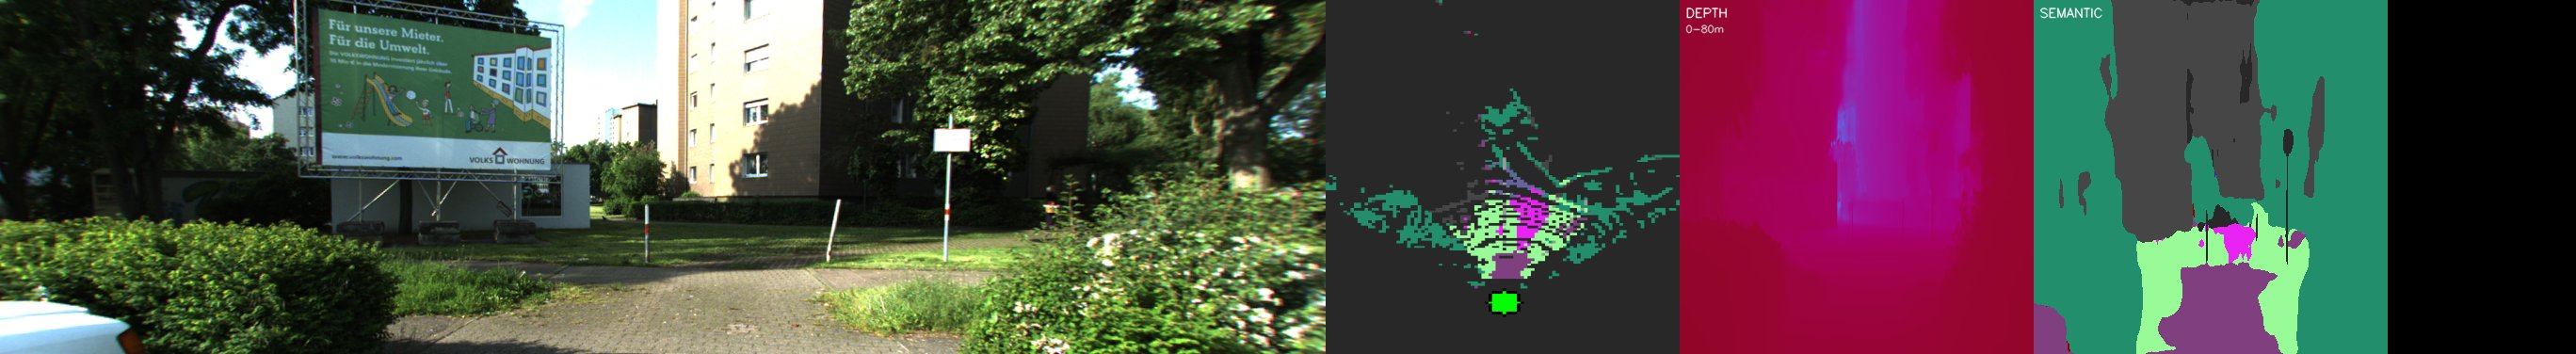

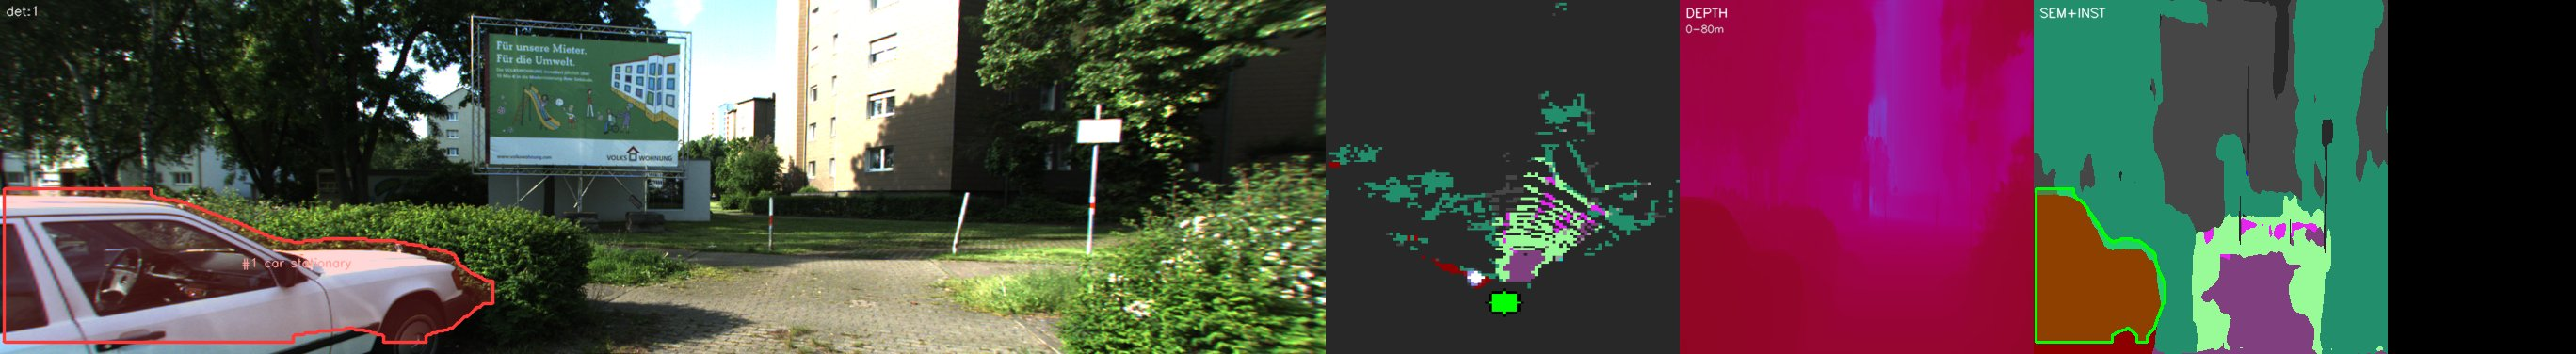

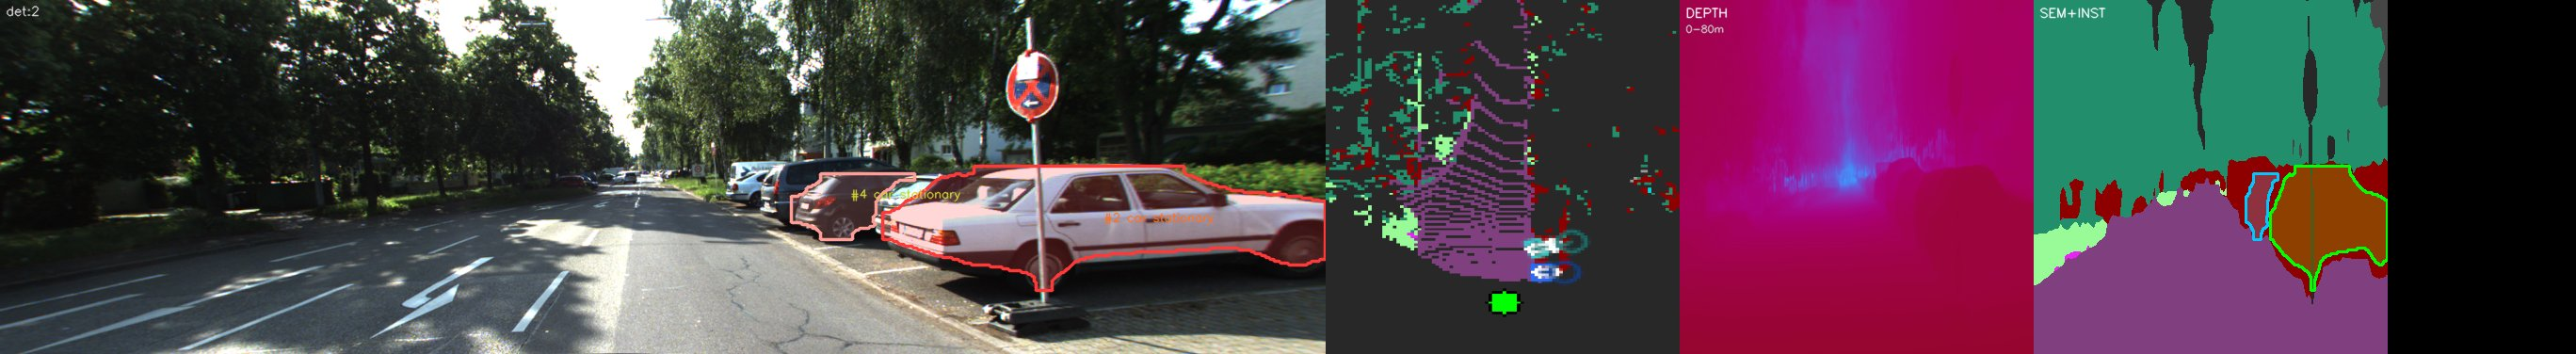

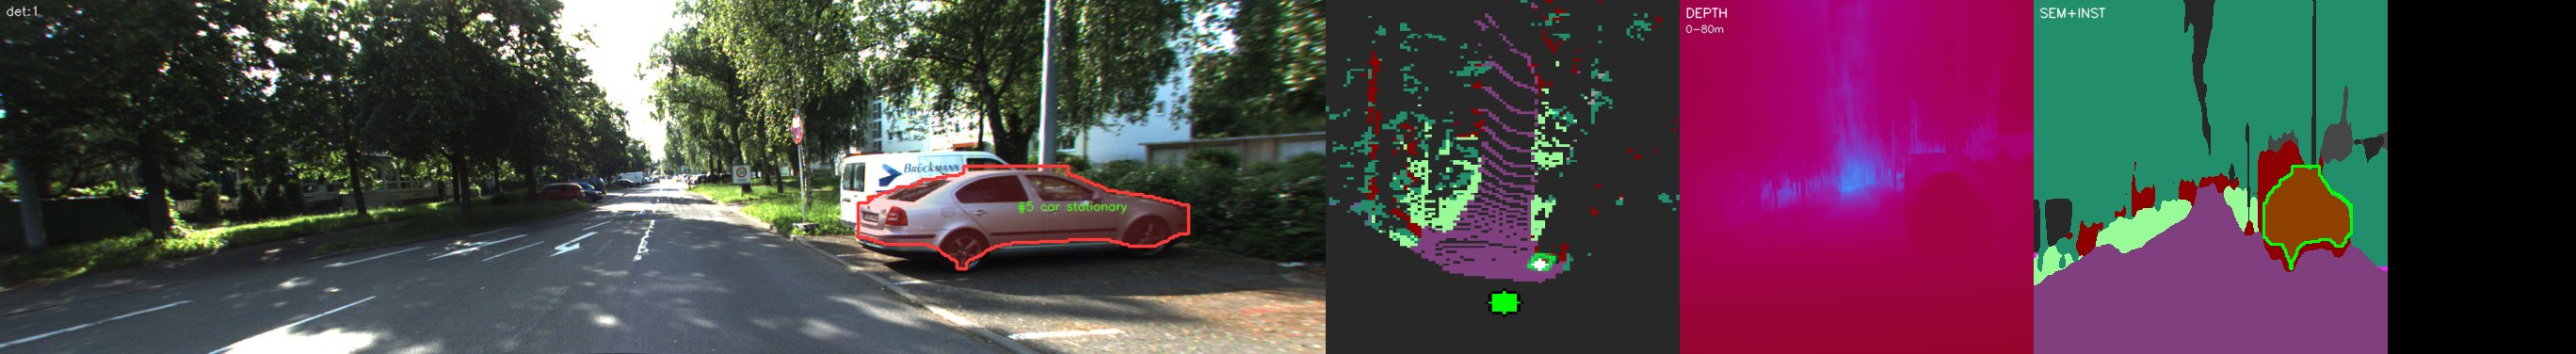

{'allocated_gb': 0.157063168,
 'reserved_gb': 0.207618048,
 'free_gb': 23.451533312,
 'total_gb': 23.65915136}

In [10]:
# Inference -- detection + tracking (Pass 1)
# For KITTI-360: reads frames directly from Drive (no MP4 needed).

import gc, torch, cv2, numpy as np
from pathlib import Path
from omegaconf import OmegaConf
from fusion_perception.tracking.kalman_cowtracker import KalmanCoWTracker
from fusion_perception.tracking.ego_motion import PoseEgoCompensation
from fusion_perception.segmentation.road_segmentor import RoadSegmentor
from fusion_perception.occupancy.bev_grid import OccupancyBEVGenerator
from fusion_perception.tracking.trajectory_manager import SceneMemoryManager
from fusion_perception.models.gemma_wrapper import GemmaReasoningWrapper
from fusion_perception.pipelines.stage_runner import StageRunner
from fusion_perception.utils.json_io import save_detections, save_tracks
from fusion_perception.utils.memory_monitor import log_gpu_memory
from fusion_perception.data.lidar_loader import load_bin, load_bin_4col

try:
    from tqdm.notebook import tqdm as _tqdm
except ImportError:
    def _tqdm(it, **kw): return it

cfg = OmegaConf.merge(
    OmegaConf.load('configs/default.yaml'),
    OmegaConf.load('configs/colab.yaml'),
)

_CLASSES = ["car", "person", "cyclist", "truck", "bus", "motorcycle"]

# -- Detector -----------------------------------------------------------------
from fusion_perception.models.frustum_detector import FrustumLidarDetector

_fd = cfg.get('frustum', OmegaConf.create({
    'model_id': 'yolo26n.pt', 'seg_model_id': 'yolo26n-seg.pt',
    'use_keypoints': True, 'score_threshold': 0.30, 'min_frustum_pts': 5
}))
detector = FrustumLidarDetector(
    model_id=_fd.model_id,
    seg_model_id=_fd.get('seg_model_id', 'yolo26n-seg.pt'),
    use_keypoints=bool(_fd.get('use_keypoints', True)),
    score_threshold=_fd.score_threshold,
    min_frustum_pts=_fd.min_frustum_pts,
    device=cfg.tracking.device,
)
detector.load()

# -- Tracker ------------------------------------------------------------------
tracker = KalmanCoWTracker(
    window_size=cfg.tracking.window_size, max_tracks=cfg.tracking.max_tracks,
    lost_patience=cfg.tracking.lost_patience, confirm_age=cfg.tracking.confirm_age,
    high_score_threshold=cfg.tracking.high_score_threshold,
    low_score_threshold=cfg.tracking.low_score_threshold,
    assignment_cost_threshold=cfg.tracking.assignment_cost_threshold,
    alpha_cost=cfg.tracking.alpha_cost, cow_conf_threshold=cfg.tracking.cow_conf_threshold,
    min_cow_points=cfg.tracking.min_cow_points, velocity_decay=cfg.tracking.velocity_decay,
    ego_motion=cfg.tracking.ego_motion, mahal_threshold=cfg.tracking.mahal_threshold,
    lazy_cow_innovation=cfg.tracking.lazy_cow_innovation, device=cfg.tracking.device,
)
tracker.load()
if hasattr(tracker, 'cow_active'):
    if tracker.cow_active:
        print('CoWTracker loaded — hybrid KF+pixel mode active')
    else:
        print('WARNING: CoWTracker DEGRADED (KF-only mode).')

# -- BEV, memory, Gemma -------------------------------------------------------
bev_gen   = OccupancyBEVGenerator(resolution=cfg.occupancy.resolution,
                                   x_range=list(cfg.occupancy.x_range),
                                   z_range=list(cfg.occupancy.z_range),
                                   decay_factor=cfg.occupancy.decay_factor,
                                   lidar_confidence=cfg.occupancy.lidar_confidence)
scene_mem = SceneMemoryManager()

r_cfg = cfg.reasoning
gemma = GemmaReasoningWrapper(
    model_id=r_cfg.model_id,
    quantize_4bit=r_cfg.quantize_4bit,
    max_new_tokens=r_cfg.max_new_tokens,
    device=r_cfg.device,
    visual_mode=r_cfg.get('visual_mode', True),
    rolling_frames=r_cfg.get('rolling_frames', 3),
    visual_token_budget=r_cfg.get('visual_token_budget', 70),
)
print(f'Gemma reasoning mode: visual ×{r_cfg.get("rolling_frames",3)} @ {r_cfg.get("visual_token_budget",70)} tok/img')
log_gpu_memory('Pass-1 models loaded (Gemma deferred)')

# -- Road / semantic segmentor ------------------------------------------------
road_seg = RoadSegmentor(device=cfg.tracking.device)
road_seg.load()
print('Road segmentor loaded (YOLO26n-sem Cityscapes)')

# -- Depth pipeline -----------------------------------------------------------
depth_estimator = depth_quality_gate = lidar_anchor_obj = None
depth_cfg = cfg.get('depth', None)
_depth_enabled = (
    bool(depth_cfg.enabled)
    if depth_cfg is not None and hasattr(depth_cfg, 'enabled')
    else False
)
print(f'Depth pipeline enabled: {_depth_enabled}')
if _depth_enabled:
    from fusion_perception.depth.mono_depth_estimator import MonoDepthEstimator
    from fusion_perception.depth.quality_gate import DepthQualityGate
    from fusion_perception.depth.lidar_anchor import LidarDepthAnchor
    _model_size = depth_cfg.get('model_size', 'small') if hasattr(depth_cfg, 'get') else 'small'
    depth_estimator = MonoDepthEstimator(model_size=_model_size, device=str(cfg.tracking.device))
    depth_estimator.load()
    depth_quality_gate = DepthQualityGate()
    lidar_anchor_obj = LidarDepthAnchor()
    print(f'Depth pipeline loaded (DA-V2 {_model_size} + LiDAR anchor)')

# -- Pipeline runner ----------------------------------------------------------
runner = StageRunner(
    detector=detector, tracker=tracker, bev_generator=bev_gen,
    scene_memory=scene_mem, gemma=gemma,
    prompts=_CLASSES, reasoning_interval=REASONING_INTERVAL,
    fps=KITTI_FPS, visual_reasoning=True,
    road_segmentor=road_seg, road_seg_interval=5,
    depth_estimator=depth_estimator,
    depth_quality_gate=depth_quality_gate,
    lidar_anchor=lidar_anchor_obj,
    calib=calib,
)

# -- Ego-motion compensator ---------------------------------------------------
ego_comp = None
if DATA_FORMAT == '360' and 'gt_labels' in dir() and gt_labels is not None:
    _T_pose = calib.T_pose_to_cam if hasattr(calib, 'T_pose_to_cam') else gt_labels._T_pose_to_cam
    _R_rect = calib.R_rect if hasattr(calib, 'R_rect') else gt_labels._R_rect
    ego_comp = PoseEgoCompensation(gt_labels.poses, _T_pose, _R_rect)
    print(f'Ego-motion compensation: pose-based ({len(gt_labels.poses)} pose frames)')
else:
    print('Ego-motion compensation: disabled')

# -- Frame source -------------------------------------------------------------
if DATA_FORMAT == '360':
    from fusion_perception.data.kitti360_frame_loader import Kitti360FrameLoader
    frame_loader  = Kitti360FrameLoader(KITTI360_ROOT, KITTI360_SEQ, max_frames=MAX_FRAMES)
    _s            = cv2.imread(left_imgs[0])
    H, W          = _s.shape[:2]
    TOTAL_FRAMES  = len(left_imgs) if MAX_FRAMES is None else min(MAX_FRAMES, len(left_imgs))
else:
    from fusion_perception.utils.video_loader import VideoLoader
    frame_loader  = VideoLoader(source=VIDEO_PATH, resize_hw=None, max_frames=MAX_FRAMES)
    _cap          = cv2.VideoCapture(VIDEO_PATH)
    H             = int(_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    W             = int(_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    TOTAL_FRAMES  = int(_cap.get(cv2.CAP_PROP_FRAME_COUNT))
    _cap.release()

_depth_panel_w = H if _depth_enabled else 0
_sem_panel_w   = H
_composite_w   = W + H + _depth_panel_w + _sem_panel_w + 200

out_video = cv2.VideoWriter(
    str(out_dir / 'output.mp4'), cv2.VideoWriter_fourcc(*'mp4v'),
    KITTI_FPS, (_composite_w, H),
)
debug_dir = out_dir / 'debug_frames'
debug_dir.mkdir(exist_ok=True)

all_detections, all_tracks = {}, {}
pending_memories = []
FLUSH = cfg.output.flush_interval
n_errors = 0
last_frame_idx = -1

print(f'Pass 1: detection + tracking  ({TOTAL_FRAMES} frames total)')
print(f'Composite layout: {W}px frame | {H}px BEV | {_depth_panel_w}px depth | {_sem_panel_w}px semantic | 200px text')
pbar = _tqdm(frame_loader, total=TOTAL_FRAMES, desc='Pass 1', unit='fr')
for frame_idx, frame_rgb, meta in pbar:
    try:
        lidar_path     = lidar_seq.get_path(frame_idx) if lidar_seq else None
        lidar_pts_velo = load_bin_4col(lidar_path) if lidar_path else None
        lidar_pts_cam  = calib.velo_to_cam(lidar_pts_velo[:, :3]) if lidar_pts_velo is not None else None
        T_ego          = ego_comp.get_transform(frame_idx) if ego_comp is not None else None
        outputs        = runner.run_frame(
            frame_rgb, frame_idx, intrinsics=K,
            lidar_pts=lidar_pts_cam,
            lidar_pts_velo=lidar_pts_velo,
            T_ego=T_ego,
        )

        all_detections[frame_idx] = outputs['detections']
        for t in outputs['tracks']:
            all_tracks[t.track_id] = t

        if frame_idx % REASONING_INTERVAL == 0:
            pending_memories.append((frame_idx, outputs['memory']))

        out_video.write(outputs['composite'][:, :, ::-1])

        if SAVE_DEBUG_FRAMES and frame_idx % DEBUG_EVERY == 0:
            dbg_path = debug_dir / f'frame_{frame_idx:06d}.jpg'
            cv2.imwrite(str(dbg_path), outputs['composite'][:, :, ::-1],
                        [cv2.IMWRITE_JPEG_QUALITY, 85])

        if (frame_idx + 1) % FLUSH == 0:
            save_detections(out_dir / 'detections.json', run_id, str(out_dir),
                            _CLASSES, all_detections)
            save_tracks(out_dir / 'tracks.json', run_id, all_tracks)

        last_frame_idx = frame_idx
        pbar.set_postfix(dets=len(outputs['detections']),
                         tracks=len(outputs['tracks']), err=n_errors)

    except KeyboardInterrupt:
        print('\nInterrupted.')
        break
    except Exception as exc:
        n_errors += 1
        print(f'  WARNING frame {frame_idx}: {exc}')
        if n_errors >= 15:
            print('Too many errors -- stopping pass 1.')
            break

out_video.release()
save_detections(out_dir / 'detections.json', run_id, str(out_dir),
                _CLASSES, all_detections)
save_tracks(out_dir / 'tracks.json', run_id, all_tracks)
print(f'Pass 1 done -- {last_frame_idx+1} frames  '
      f'{len(all_tracks)} tracks  {n_errors} errors')

if SHOW_DEBUG:
    import glob as _glob
    from IPython.display import display, Image as _Img
    saved = sorted(_glob.glob(str(debug_dir / '*.jpg')))[:4]
    print(f'Sample frames ({len(saved)} shown):')
    for p in saved:
        display(_Img(filename=p, width=900))

detector.unload()
try: tracker.unload()
except AttributeError: pass
road_seg.unload()
if depth_estimator is not None:
    try: depth_estimator.unload()
    except AttributeError: pass
torch.cuda.empty_cache()
log_gpu_memory('After pass 1 -- GPU freed')

config.json:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/10.2G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/208 [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json:   0%|          | 0.00/32.2M [00:00<?, ?B/s]

Reasoning mode: text-only  |  max_new_tokens=120
Reasoning on 34 snapshots...


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


  [  1/34] f   0  5365ms
           SUMMARY    : Low vegetation and terrain present; no moving objects.
           TRAJECTORY : Clear road ahead, safe to continue at speed.
  [  2/34] f  15  4626ms
           SUMMARY    : Low vegetation and terrain present, no moving objects.
           TRAJECTORY : Clear road ahead, safe to continue at speed.
  [  3/34] f  30  6334ms
           SUMMARY    : One car approaching at 2m/s from the edge.
           ANOMALY    : Car approaching at 2m/s from the edge.
           TRAJECTORY : Maintain speed, watch the approaching vehicle.
  [  4/34] f  45  5549ms
           SUMMARY    : One car near, stationary at edge of road.
           ANOMALY    : Car stationary near edge; maintain safe distance.
           TRAJECTORY : Maintain speed, watch the stationary vehicle.
  [  5/34] f  60  5191ms
           SUMMARY    : One car stationary near the road edge.
           ANOMALY    : Maintain safe distance from the stationary car.
           TRAJECTORY : Maintain 

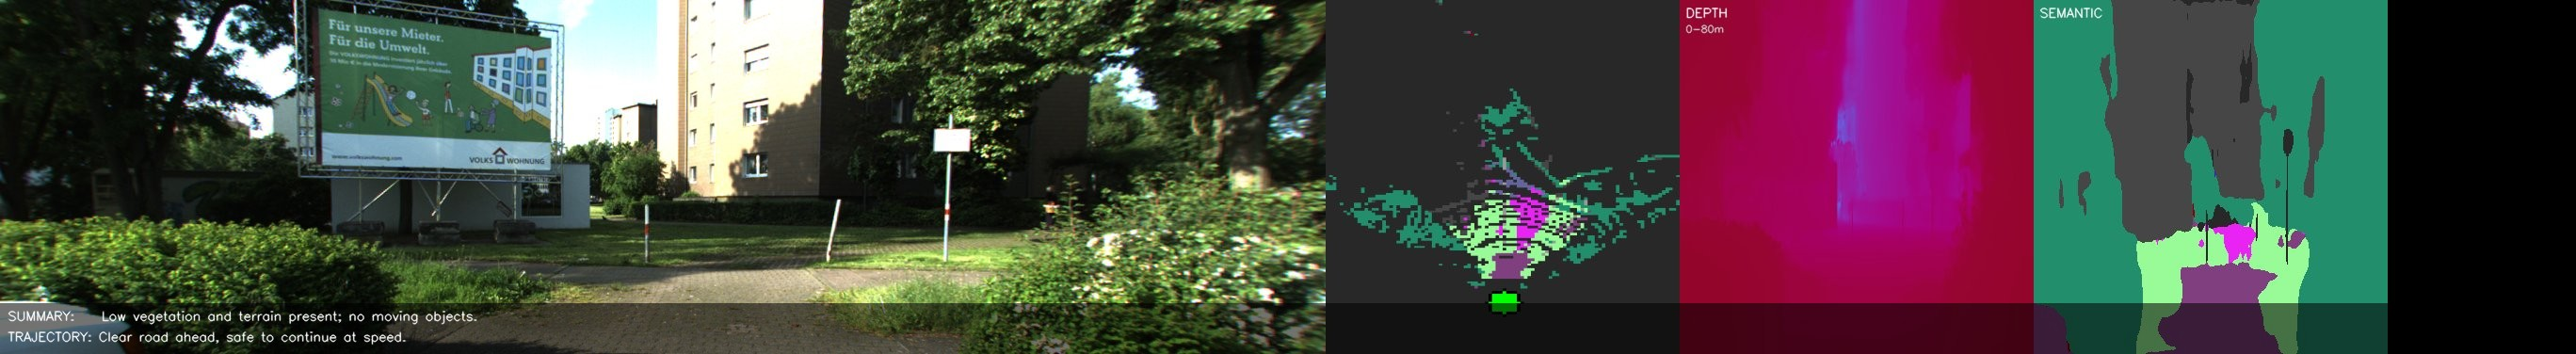

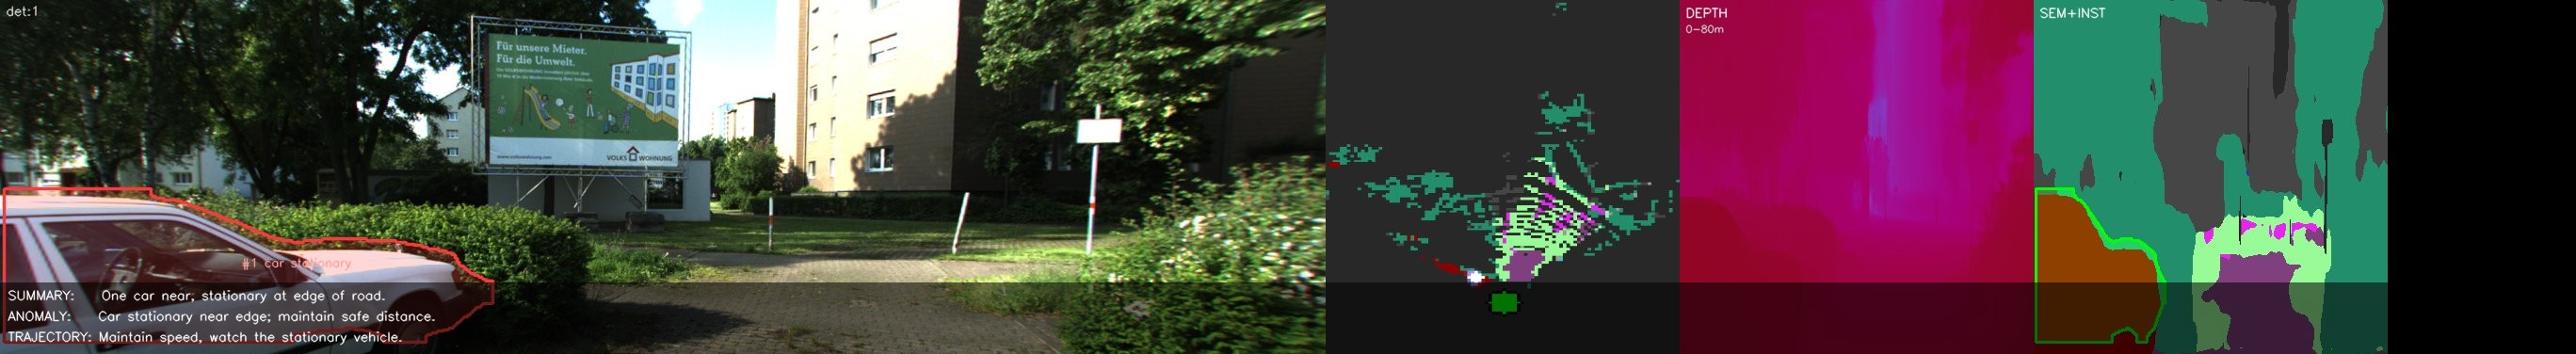

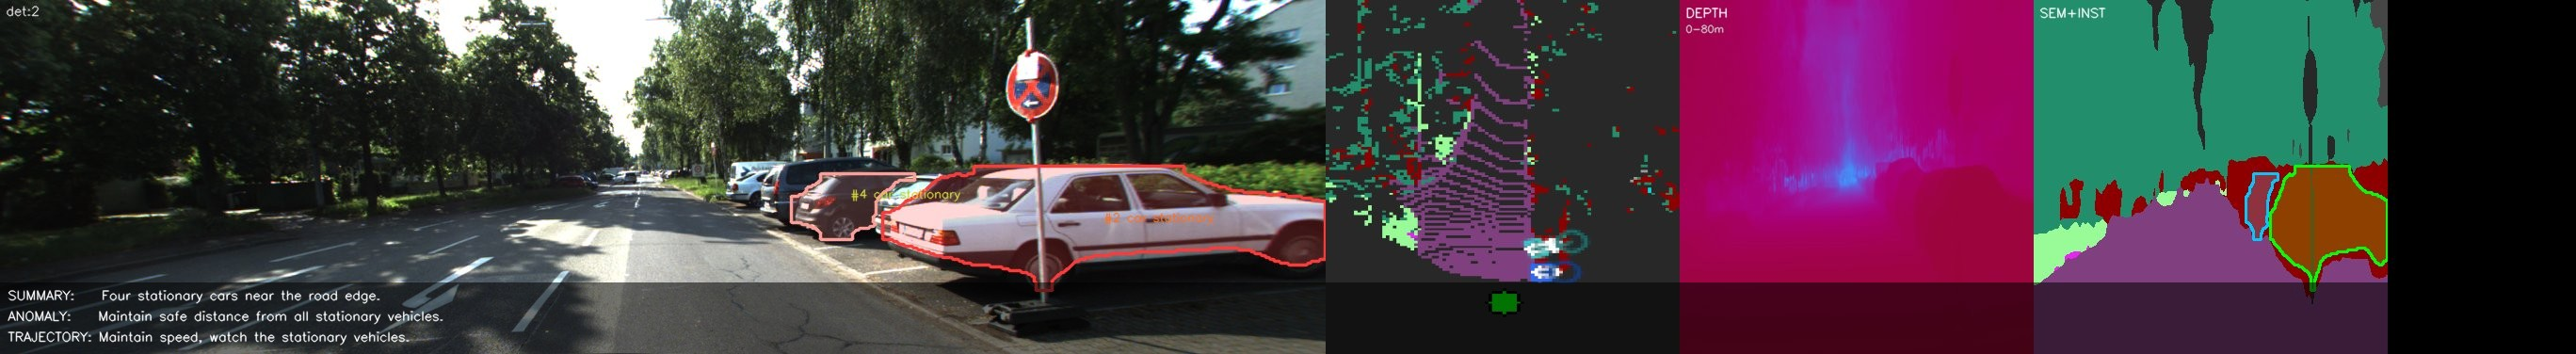

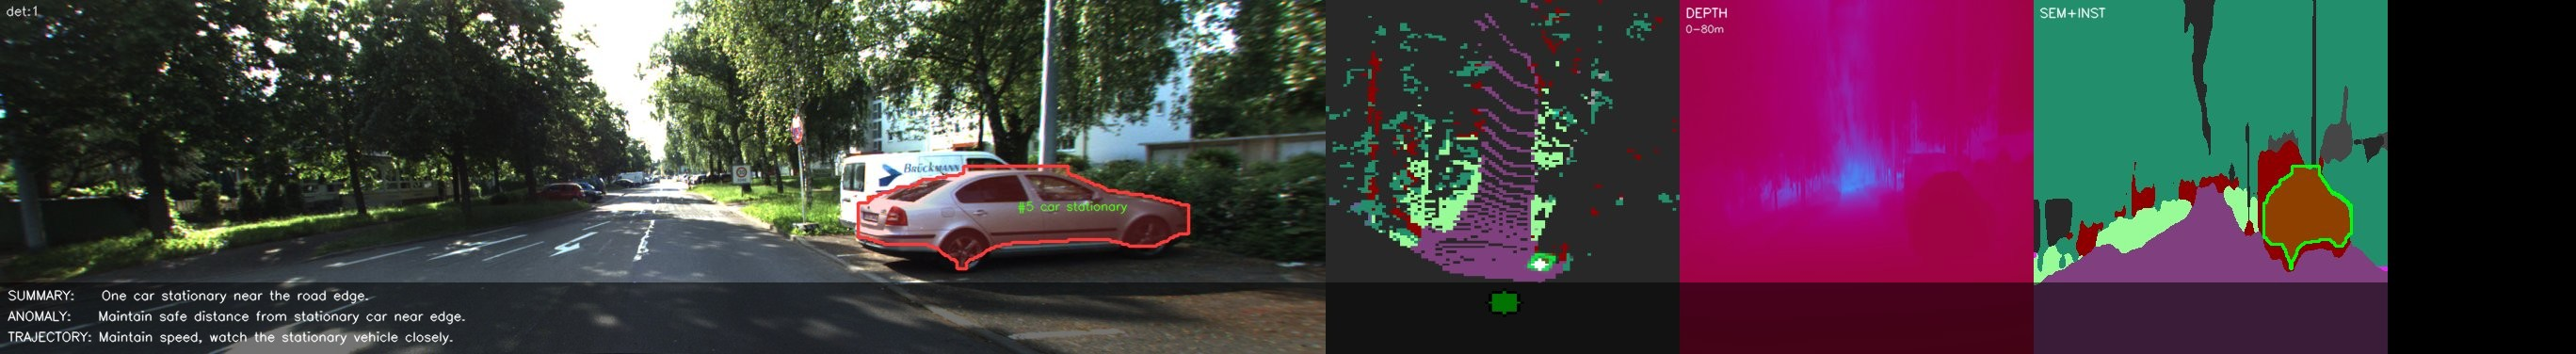

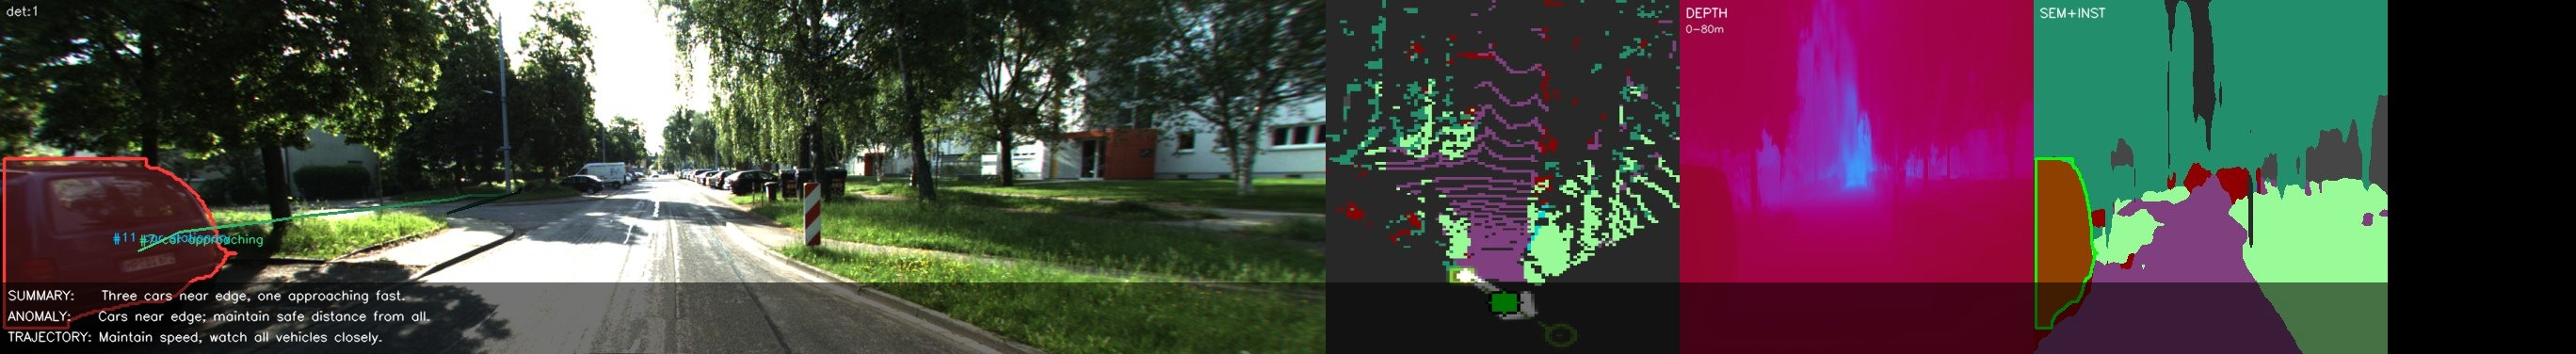

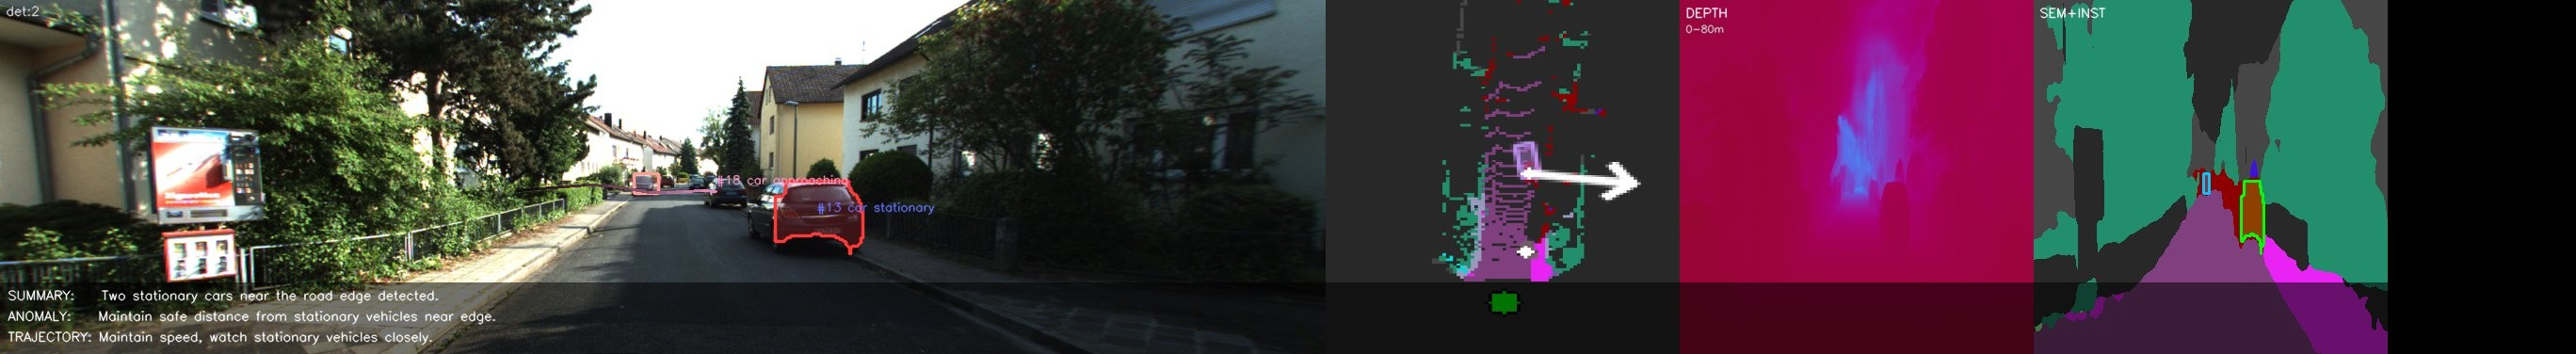

In [11]:
# Pass 2 — Gemma reasoning (re-run any time)

import torch, cv2, numpy as np
from pathlib import Path
from fusion_perception.models.gemma_wrapper import GemmaReasoningWrapper
from fusion_perception.memory.gemma_memory import GemmaMemoryBuffer
from fusion_perception.utils.json_io import save_reasoning
from fusion_perception.utils.memory_monitor import log_gpu_memory
from omegaconf import OmegaConf
from IPython.display import display, Image as _Img

cfg = OmegaConf.merge(
    OmegaConf.load('configs/default.yaml'),
    OmegaConf.load('configs/colab.yaml'),
)
r_cfg = cfg.reasoning
gemma = GemmaReasoningWrapper(
    model_id=r_cfg.model_id,
    quantize_4bit=r_cfg.quantize_4bit,
    max_new_tokens=r_cfg.max_new_tokens,
    device=r_cfg.device,
    visual_mode=r_cfg.get('visual_mode', True),
    rolling_frames=r_cfg.get('rolling_frames', 3),
    visual_token_budget=r_cfg.get('visual_token_budget', 70),
)
gemma.load()
log_gpu_memory('Gemma loaded')

_visual_str = (
    f'visual ×{r_cfg.get("rolling_frames", 3)} frames '
    f'@ {r_cfg.get("visual_token_budget", 70)} tok/img'
    if r_cfg.get('visual_mode', True) else 'text-only'
)
print(f'Reasoning mode: {_visual_str}  |  max_new_tokens={r_cfg.max_new_tokens}')

gemma_memory = GemmaMemoryBuffer(maxlen=5)
all_reasoning = []
print(f'Reasoning on {len(pending_memories)} snapshots...')
for i, (fidx, memory) in enumerate(pending_memories):
    try:
        mem_prefix = gemma_memory.format_prefix(fidx, KITTI_FPS)
        r = gemma.reason(memory, None, trigger_reason='interval', fps=KITTI_FPS,
                         memory_prefix=mem_prefix)
        if r is not None:
            all_reasoning.append(r)
            gemma_memory.add(r, [], fidx, KITTI_FPS)
            anom_str = f'\n           ANOMALY    : {r.anomalies[0]}' if r.anomalies else ''
            traj_str = f'\n           TRAJECTORY : {r.trajectory_nl}' if r.trajectory_nl else ''
            print(f'  [{i+1:3d}/{len(pending_memories)}] f{fidx:4d} {r.latency_ms:5.0f}ms'
                  f'\n           SUMMARY    : {r.summary}'
                  f'{anom_str}{traj_str}')
    except Exception as exc:
        print(f'  WARNING frame {fidx}: {exc}')

save_reasoning(out_dir / 'reasoning.json', run_id, REASONING_INTERVAL, all_reasoning)
print(f'\nSaved {len(all_reasoning)} reasoning outputs -> {out_dir / "reasoning.json"}')

gemma.unload()
torch.cuda.empty_cache()
log_gpu_memory('Gemma unloaded')

# ── Overlay reasoning onto saved debug frames ─────────────────────────────────
# The video was written in Pass 1 before reasoning ran (two-pass design).
# Here we annotate the debug frames with SUMMARY / ANOMALY / TRAJECTORY text
# and display them so the reasoning is visible alongside the scene.
import glob as _glob

_debug_frames = sorted(_glob.glob(str(out_dir / 'debug_frames' / 'frame_*.jpg')))
if _debug_frames and all_reasoning:
    _reasoning_map  = {r.frame_idx: r for r in all_reasoning}
    _reasoning_keys = sorted(_reasoning_map)

    def _nearest(fidx):
        candidates = [k for k in _reasoning_keys if k <= fidx]
        return _reasoning_map[candidates[-1]] if candidates else None

    print(f'\nAnnotated debug frames ({min(len(_debug_frames), 6)} shown):')
    for dbg_path in _debug_frames[:6]:
        fidx = int(Path(dbg_path).stem.replace('frame_', ''))
        r = _nearest(fidx)
        img = cv2.imread(dbg_path)
        H, W = img.shape[:2]

        if r is not None:
            lines = [f'SUMMARY:    {r.summary}']
            if r.anomalies:
                lines.append(f'ANOMALY:    {r.anomalies[0]}')
            if r.trajectory_nl:
                lines.append(f'TRAJECTORY: {r.trajectory_nl}')

            bar_h = len(lines) * 22 + 10
            overlay = img.copy()
            cv2.rectangle(overlay, (0, H - bar_h), (W, H), (0, 0, 0), -1)
            cv2.addWeighted(overlay, 0.55, img, 0.45, 0, img)

            for j, line in enumerate(lines):
                cv2.putText(img, line, (8, H - bar_h + 18 + j * 22),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)

        out_path = str(out_dir / 'debug_frames' / f'captioned_{fidx:06d}.jpg')
        cv2.imwrite(out_path, img, [cv2.IMWRITE_JPEG_QUALITY, 90])
        display(_Img(filename=out_path, width=900))

In [ ]:
# 3D LiDAR Map — accumulate world-frame point cloud and save / render
#
# Requires: Pass 1 complete (all_detections, lidar_seq, calib, gt_labels)
# Outputs:
#   outputs/<run_id>/lidar_map.ply    — download for interactive viewing in MeshLab
#   outputs/<run_id>/map_topdown.png  — matplotlib top-down BEV (shown in notebook)
#   outputs/<run_id>/map_side.png     — matplotlib side view
#
# Note: Open3D OffscreenRenderer (EGL) crashes Colab kernels when EGL is
# unavailable. All rendering is done with matplotlib instead — no EGL needed.

import numpy as np
import open3d as o3d
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from IPython.display import display, Image as _Img
from fusion_perception.data.lidar_loader import load_bin_4col

VOXEL_SIZE    = 0.10
Z_MIN, Z_MAX  = -2.0, 8.0
CHUNK_FRAMES  = 50

def _height_colors(pts):
    t = np.clip((pts[:, 2] - Z_MIN) / (Z_MAX - Z_MIN), 0.0, 1.0)
    return cm.plasma(t)[:, :3].astype(np.float32)

# ── Guards ────────────────────────────────────────────────────────────────────
if 'lidar_seq' not in dir() or lidar_seq is None:
    print('LiDAR not available — run cell-lidar-calib with DOWNLOAD_LIDAR=True first.')
    raise SystemExit(0)
if 'gt_labels' not in dir() or gt_labels is None or not gt_labels.poses:
    print('gt_labels.poses not available — run cell-kitti360-labels first.')
    raise SystemExit(0)
if 'all_detections' not in dir() or not all_detections:
    print('all_detections not defined — run cell-inference (Pass 1) first.')
    raise SystemExit(0)

# Velodyne → IMU → world with KITTI-360's calibration (see
# fusion_perception/mapping/lidar_map.py). Replaces the old chain, which mixed
# the rectified camera frame with the unrectified camera→pose transform.
from fusion_perception.mapping.lidar_map import LidarWorldMap, velo_to_pose
import os as _os

world_map = LidarWorldMap(gt_labels.poses,
                          velo_to_pose(_os.path.join(KITTI360_ROOT, 'calibration')),
                          voxel=VOXEL_SIZE, chunk_frames=CHUNK_FRAMES)
frame_indices = sorted(all_detections.keys())
print(f'Building LiDAR world map from {len(frame_indices)} processed frames ...')
for frame_idx in frame_indices:
    lidar_path = lidar_seq.get_path(frame_idx)
    if lidar_path is not None:
        world_map.add_scan(frame_idx, load_bin_4col(lidar_path))
pts = world_map.points()
if not len(pts):
    print('No frames matched LiDAR + pose data.')
    raise SystemExit(0)
print(f'  {len(world_map.frames_used)} frames used, {len(pts):,} points after downsample')
cols = _height_colors(pts)
pcd_ds = o3d.geometry.PointCloud()
pcd_ds.points = o3d.utility.Vector3dVector(pts)
pcd_ds.colors = o3d.utility.Vector3dVector(cols)
print(f'  {len(pts):,} points after downsample')

# ── Save .ply ─────────────────────────────────────────────────────────────────
ply_path = str(out_dir / 'lidar_map.ply')
o3d.io.write_point_cloud(ply_path, pcd_ds)
print(f'  Saved: {ply_path}')
print('  → Download and open in MeshLab / CloudCompare for interactive 3D view.')

# ── Top-down BEV (matplotlib — no EGL needed) ─────────────────────────────────
print('\nRendering top-down BEV ...')
fig, ax = plt.subplots(figsize=(14, 14), facecolor='black')
ax.set_facecolor('black')
ax.scatter(pts[:, 0], pts[:, 1], c=cols, s=0.05, linewidths=0)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('LiDAR World Map — Top-down BEV (KITTI-360 world frame)', color='white', fontsize=13)
topdown_path = str(out_dir / 'map_topdown.png')
plt.savefig(topdown_path, dpi=150, bbox_inches='tight', facecolor='black')
plt.show()
display(_Img(filename=topdown_path, width=900))
print(f'  Saved: {topdown_path}')

# ── Side view: X (east) vs Z (up) ─────────────────────────────────────────────
print('Rendering side view ...')
fig, ax = plt.subplots(figsize=(14, 5), facecolor='black')
ax.set_facecolor('black')
ax.scatter(pts[:, 0], pts[:, 2], c=cols, s=0.03, linewidths=0)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('LiDAR World Map — Side view (world X vs Z)', color='white', fontsize=13)
side_path = str(out_dir / 'map_side.png')
plt.savefig(side_path, dpi=150, bbox_inches='tight', facecolor='black')
plt.show()
display(_Img(filename=side_path, width=900))
print(f'  Saved: {side_path}')

print(f'\nMap complete — {len(pts):,} pts  |  files in {out_dir}/')

# ── Place the map on a real map with KITTI-360 GPS (OXTS) ─────────────────────
# Writes georef.json, map_north_up.png, paths.geojson and map_view.html
# (OpenStreetMap + LiDAR map + driven route). Needs data_poses/<seq>/oxts.
import subprocess, sys
_r = subprocess.run([sys.executable, 'scripts/build_lidar_map.py',
                     '--kitti360-root', KITTI360_ROOT, '--seq', KITTI360_SEQ,
                     '--start', str(frame_indices[0]), '--end', str(frame_indices[-1]),
                     '--out', str(out_dir / 'map')], capture_output=True, text=True)
print(_r.stdout[-1500:] or _r.stderr[-1500:])


In [13]:
# Evaluation — mAP, MOTA/MOTP, BEV occupancy IoU

if not ENABLE_GT_EVAL or 'gt_labels' not in dir() or gt_labels is None:
    print('GT evaluation skipped (gt_labels not loaded or ENABLE_GT_EVAL=False)')
else:
    from fusion_perception.evaluation.metrics import (
        compute_detection_metrics, compute_tracking_metrics, compute_occupancy_iou,
    )
    import json as _json

    GT_EVAL_EVERY = 5
    print('Building GT label dict...')
    gt_dict = {}
    for fidx in sorted(all_detections.keys())[::GT_EVAL_EVERY]:
        labs = gt_labels.to_gt_labels(fidx)
        if labs:
            gt_dict[fidx] = labs
    print(f'  {len(gt_dict)} frames with GT boxes')

    if gt_dict:
        det_m = compute_detection_metrics(all_detections, gt_dict, iou_threshold=0.5)
        print('\n=== Detection BEV mAP@IoU0.5 ===')
        print(f'  mAP: {det_m["map"]:.4f}')
        for cls, ap in sorted(det_m['per_class_ap'].items()):
            print(f'    {cls:<20s}: AP = {ap:.4f}')

        # MOTA: restrict detections to GT-annotated frames only.
        # Using all_detections (500 frames) against gt_dict (83 frames) inflates
        # FP by ~6x because every detection in unannotated frames counts as FP.
        det_gt_frames = {k: all_detections[k] for k in gt_dict if k in all_detections}
        trk_m = compute_tracking_metrics(det_gt_frames, gt_dict, iou_threshold=0.5)
        print('\n=== Tracking (CLEAR MOT, GT-annotated frames only) ===')
        print(f'  MOTA        : {trk_m["mota"]:.4f}')
        motp_str = f'{trk_m["motp"]:.3f} m' if trk_m["motp"] > 0 else 'n/a (no TP matches)'
        print(f'  MOTP        : {motp_str}')
        print(f'  ID switches : {trk_m["id_switches"]}')
        print(f'  FP / FN     : {trk_m["fp"]} / {trk_m["fn"]}')
        print(f'  Total GT    : {trk_m["total_gt"]}')

        last_snap  = scene_mem.get_snapshot()
        last_fidx  = max(all_detections.keys())
        if last_snap is not None and last_fidx in gt_dict:
            occ_iou = compute_occupancy_iou(last_snap.occupancy_grid, gt_dict[last_fidx])
            print(f'\n=== BEV Occupancy IoU (frame {last_fidx}) ===')
            print(f'  IoU: {occ_iou:.4f}')

        with open(out_dir / 'eval_metrics.json', 'w') as _f:
            _json.dump({'detection': det_m, 'tracking': trk_m}, _f, indent=2)
        print(f'\nSaved -> {out_dir / "eval_metrics.json"}')
    else:
        print('No GT boxes found in processed frames.')

Building GT label dict...
  83 frames with GT boxes

=== Detection BEV mAP@IoU0.5 ===
  mAP: 0.0005
    bus                 : AP = 0.0000
    car                 : AP = 0.0023
    cyclist             : AP = 0.0000
    person              : AP = 0.0000
    truck               : AP = 0.0000

=== Tracking (CLEAR MOT, GT-annotated frames only) ===
  MOTA        : -0.1217
  MOTP        : 0.847 m
  ID switches : 17
  FP / FN     : 168 / 1032
  Total GT    : 1085

Saved -> outputs/2026-06-02_201954_2013_05_28_drive_0000_sync/eval_metrics.json


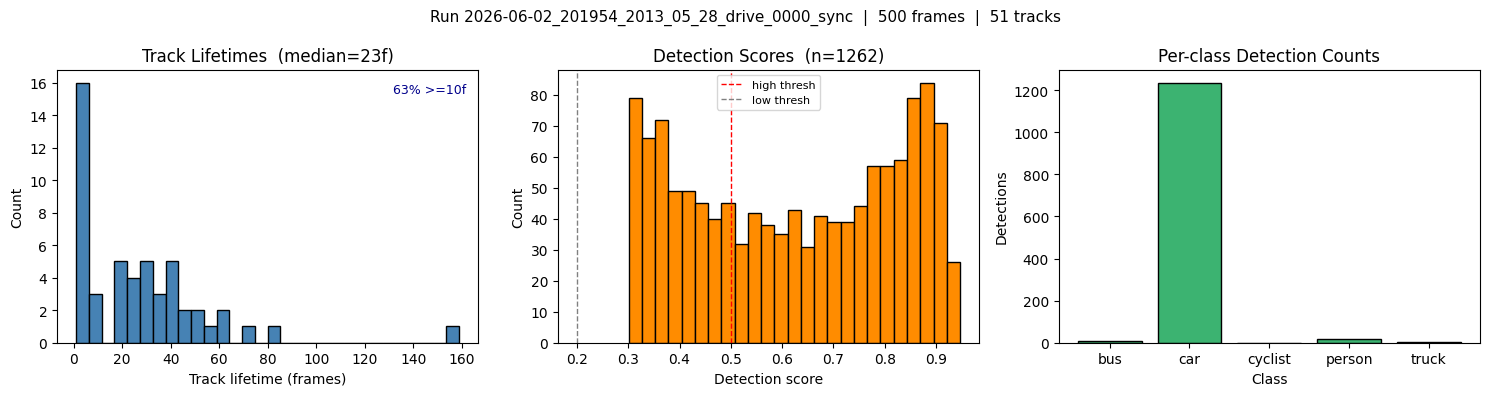

Saved -> outputs/2026-06-02_201954_2013_05_28_drive_0000_sync/stats.png

Debug frame samples (6 shown):


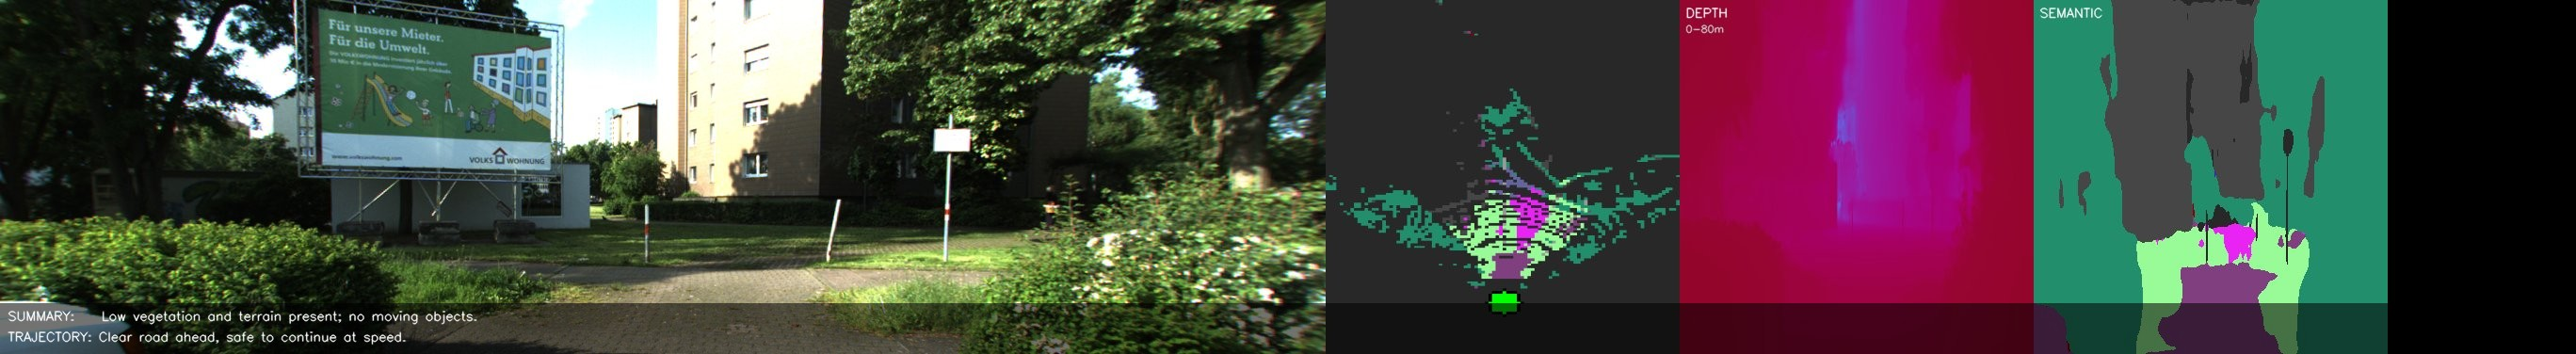

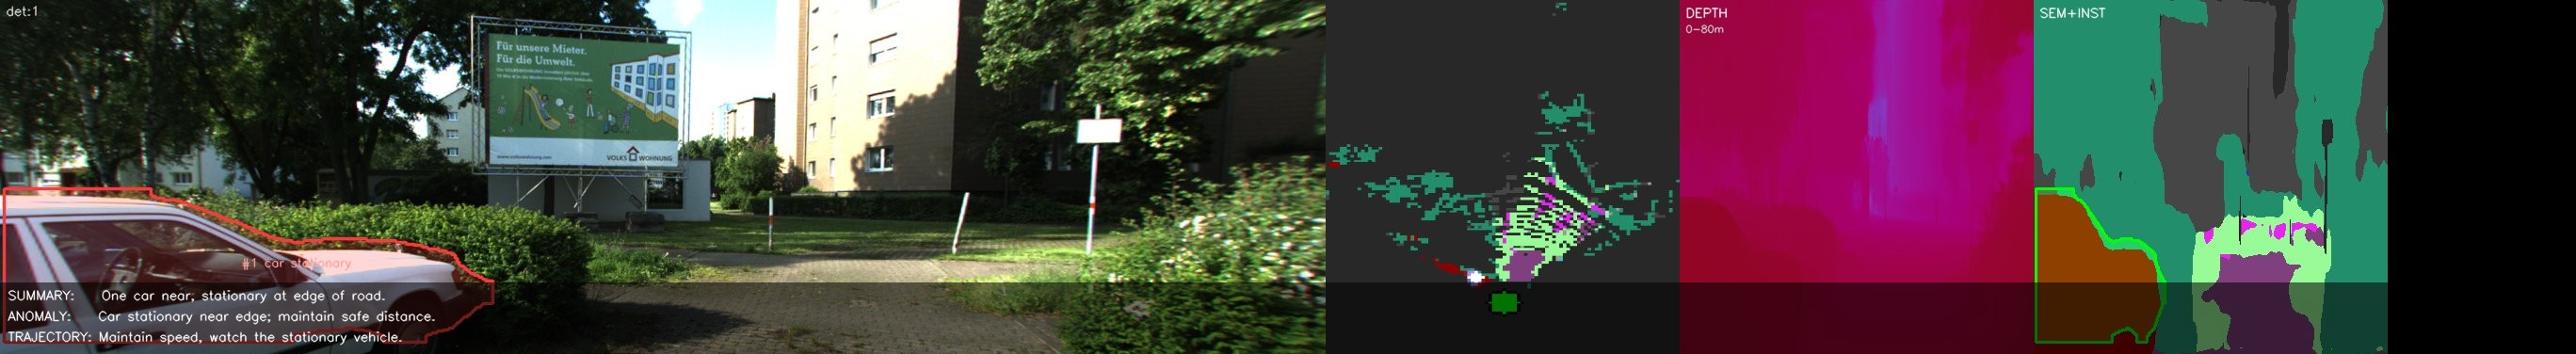

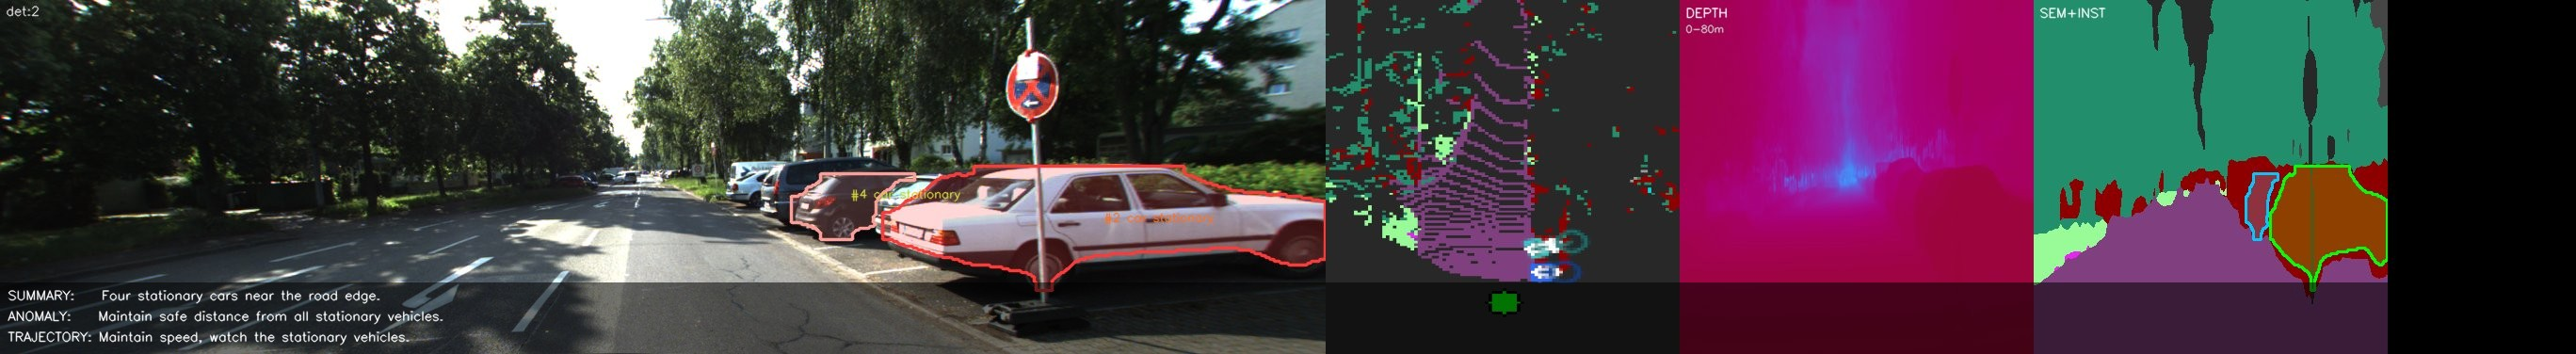

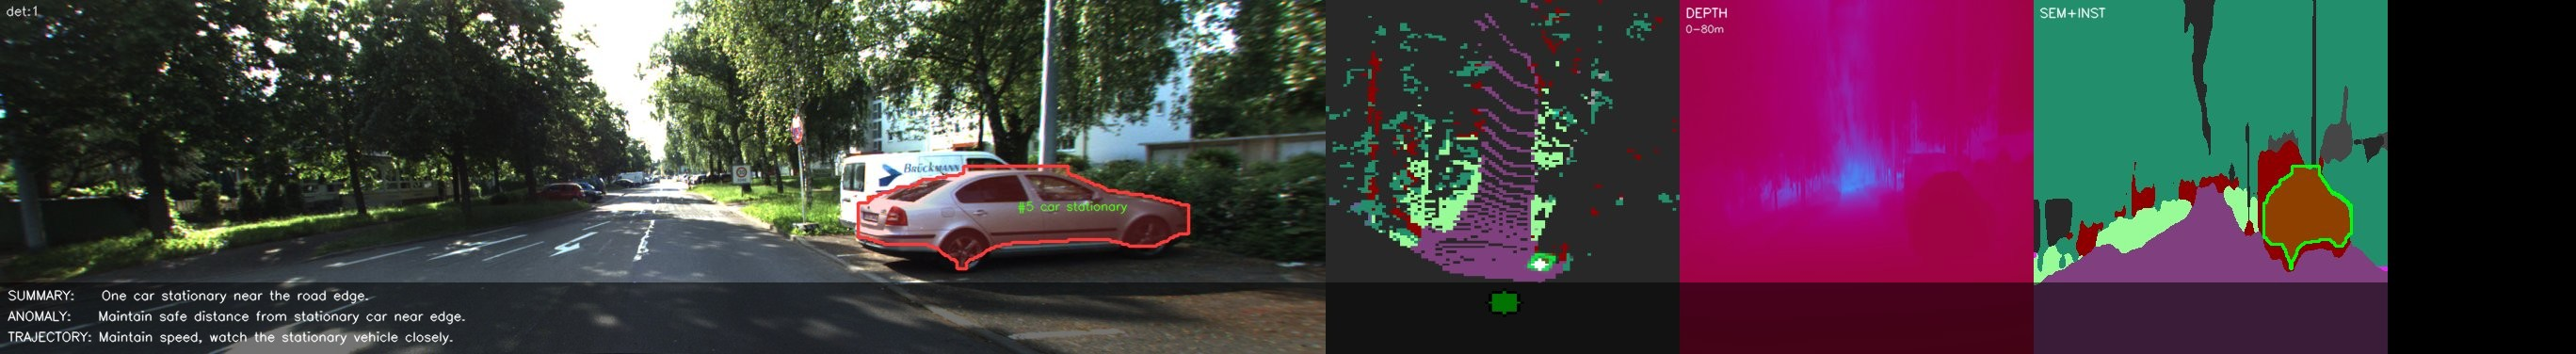

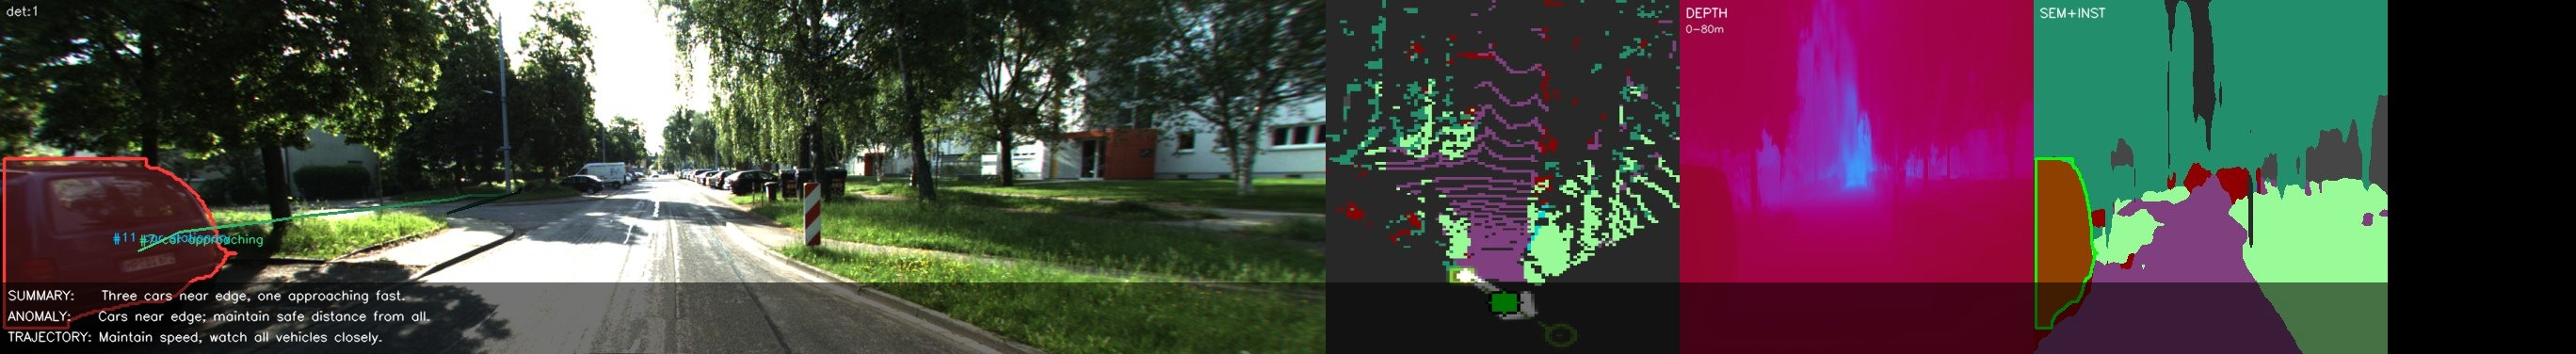

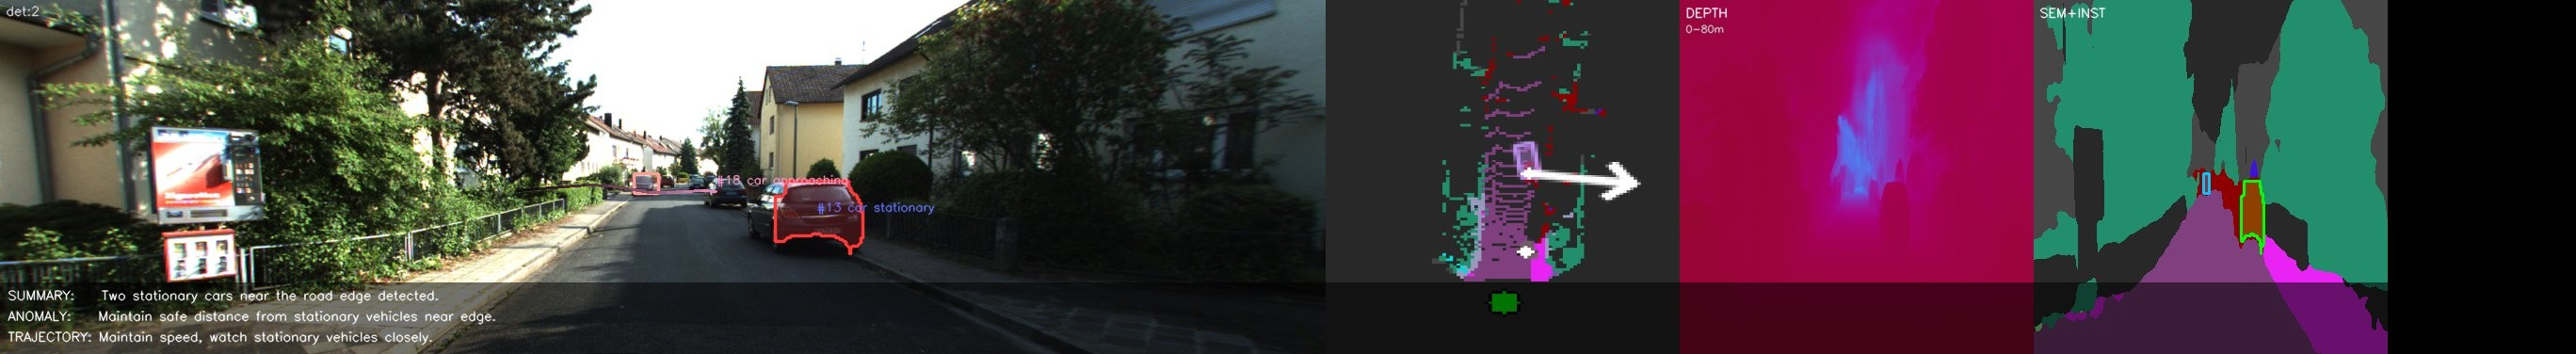


Reasoning samples:
  f   0 | Low vegetation and terrain present; no moving objects.
  f  15 | Low vegetation and terrain present, no moving objects.
  f  30 | One car approaching at 2m/s from the edge.
         ANOMALY: Car approaching at 2m/s from the edge.
  f  45 | One car near, stationary at edge of road.
         ANOMALY: Car stationary near edge; maintain safe distance.
  f  60 | One car stationary near the road edge.
         ANOMALY: Maintain safe distance from the stationary car.


In [14]:
# Visualization — tracking and detection statistics

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from IPython.display import display, Image as _Img

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle(f'Run {run_id}  |  {last_frame_idx+1} frames  |  {len(all_tracks)} tracks',
             fontsize=11)

lifetimes = [t.last_seen - t.first_seen + 1 for t in all_tracks.values()]
if lifetimes:
    axes[0].hist(lifetimes, bins=min(30, len(set(lifetimes))), edgecolor='black', color='steelblue')
    axes[0].set_xlabel('Track lifetime (frames)')
    axes[0].set_ylabel('Count')
    axes[0].set_title(f'Track Lifetimes  (median={int(np.median(lifetimes))}f)')
    pct_long = 100 * sum(1 for l in lifetimes if l >= 10) / max(len(lifetimes), 1)
    axes[0].text(0.97, 0.95, f'{pct_long:.0f}% >=10f', transform=axes[0].transAxes,
                 ha='right', va='top', fontsize=9, color='darkblue')

scores = [d.score for dets in all_detections.values() for d in dets]
if scores:
    axes[1].hist(scores, bins=25, edgecolor='black', color='darkorange')
    axes[1].set_xlabel('Detection score')
    axes[1].set_ylabel('Count')
    axes[1].set_title(f'Detection Scores  (n={len(scores)})')
    axes[1].axvline(0.5, color='red', linestyle='--', linewidth=1, label='high thresh')
    axes[1].axvline(0.2, color='gray', linestyle='--', linewidth=1, label='low thresh')
    axes[1].legend(fontsize=8)

from collections import Counter
cls_counts = Counter(d.class_name for dets in all_detections.values() for d in dets)
if cls_counts:
    classes = sorted(cls_counts.keys())
    counts  = [cls_counts[c] for c in classes]
    axes[2].bar(classes, counts, edgecolor='black', color='mediumseagreen')
    axes[2].set_xlabel('Class')
    axes[2].set_ylabel('Detections')
    axes[2].set_title('Per-class Detection Counts')

plt.tight_layout()
plot_path = str(out_dir / 'stats.png')
plt.savefig(plot_path, dpi=100, bbox_inches='tight')
plt.show()
print(f'Saved -> {plot_path}')

import glob as _glob
saved_frames = sorted(_glob.glob(str(out_dir / 'debug_frames' / '*.jpg')))
if saved_frames:
    print(f'\nDebug frame samples ({min(len(saved_frames), 6)} shown):')
    for p in saved_frames[:6]:
        display(_Img(filename=p, width=900))

if 'all_reasoning' in dir() and all_reasoning:
    print('\nReasoning samples:')
    for r in all_reasoning[:5]:
        print(f'  f{r.frame_idx:4d} | {r.summary}')
        if r.anomalies:
            print(f'         ANOMALY: {r.anomalies[0]}')
